In [ ]:
import sys
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from hcipy import * 
from psfGenerator import PsfGenerator
sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2
import scipy.ndimage

In [3]:
wavelength = 764E-9
bw = 126E-9
wavelength_normalized = wavelength / 656E-9
bw_normalized = bw / wavelength
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.5,speckle_window=70)

PsfGen = PsfGenerator(center_wavelength=wavelength_normalized,bandwidth=bw_normalized, focal_sampling=6, focal_extent=80,grating_angle=grating_angle, fx=grating_freq, fy = grating_freq, mask=True)

In [4]:
def radial_stretch_from_point(img, stretch_factor, center):
    h, w = img.shape[:2]
    cx, cy = center

    # pixel grid
    y, x = np.indices((h, w), dtype=np.float32)

    # shift relative to chosen center
    dx = x - cx
    dy = y - cy

    # scale vectors
    scale = 1 / stretch_factor

    map_x = (cx + dx * scale).astype(np.float32)
    map_y = (cy + dy * scale).astype(np.float32)
    
    stretched = cv2.remap(
        img,
        map_x,
        map_y,
        interpolation=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return stretched

/Users/Katie/Documents/MagAO-X/simulations/adc_sims/.venv/lib/python3.13/site-packages/hcipy/optics/aberration.py:38: RuntimeWarning: divide by zero encountered in power
  res = Field(grid.as_('polar').r**exponent, grid)


Text(0.5, 1.0, 'Dispersed PSF')

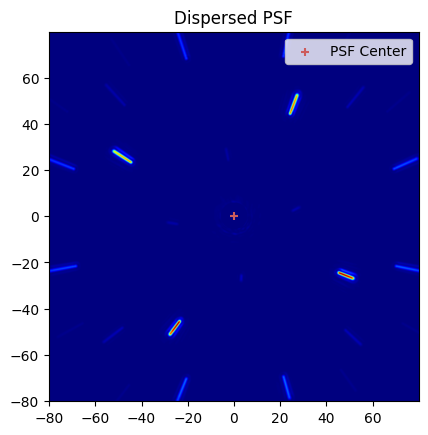

In [5]:
disp = 0.08
ang = 90-27

num_photons = 1E9
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)

true_center = np.array([0,0]) #we can worry about how well we can estimate this later


imshow_field(psf,cmap='jet')
plt.scatter(true_center[0],true_center[1],marker='+',color='indianred',label='PSF Center')
plt.legend()
plt.title('Dispersed PSF')

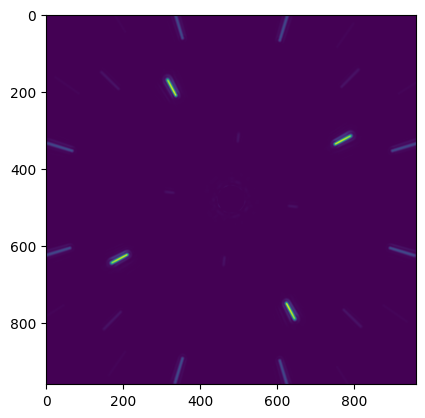

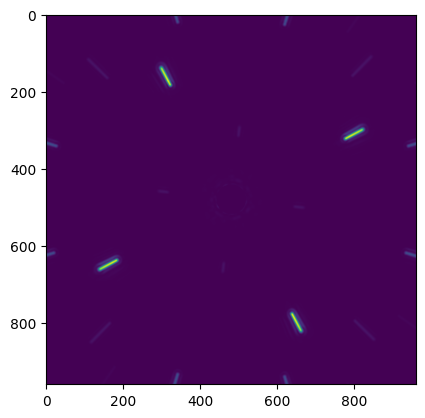

In [6]:
disp = 0.0
ang = 90-27

num_photons = 1E9
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)
center = np.array([480,480])

psf = np.array(psf.shaped)
psf_stretched = radial_stretch_from_point(psf,1.1,center=center)
plt.figure()
plt.imshow(psf)
plt.figure()
plt.imshow(psf_stretched)

In [7]:
mse = np.sum((psf - psf_stretched)**2)
print(mse)

1255.3902940943246


In [8]:
y, x = np.meshgrid(
    np.arange(460, 500),
    np.arange(460, 500),
    indexing="ij"
)

indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

In [9]:
#go through the raster and see where the mse is minimized
disp = 0.0
ang = 90-27

num_photons = 1E9
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)
center = np.array([480,480])

psf = np.array(psf.shaped)
Z = []

for index in indices:
    psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
    mse = np.sum((psf - psf_stretched)**2)
    Z.append(mse)

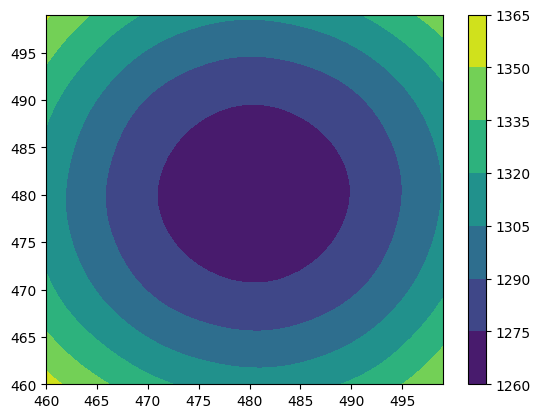

In [10]:
Z = np.array(Z)
plt.contourf(x,y,Z.reshape(y.shape))
plt.colorbar()

In [11]:
#same thing but with a dispersed PSF
disp = 0.01
ang = 90-27

num_photons = 1E9
psf = PsfGen.polar_psf(magnitude = disp,orientation = ang,num_photons=num_photons)
center = np.array([480,480])

psf = np.array(psf.shaped)
Z = []

for index in indices:
    psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
    mse = np.sum((psf - psf_stretched)**2)
    Z.append(mse)

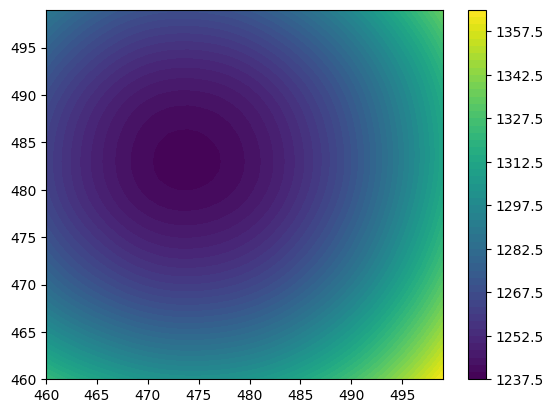

In [12]:
Z = np.array(Z)
plt.contourf(x,y,Z.reshape(y.shape),levels=50)
plt.colorbar()

looks like it's pretty easy to reproduce the result from pathak in simulation. what about on a lab image?

In [24]:
step = read_field('/Users/Katie/Documents/MagAO-X/Data/ADC/2025B/i_sparkles_counter_sat.fits')
for img in step:
    img -= np.median(img)

img = step[26]
img = ADC.crop_image(img,extent=512,mask_diam=80)
psf = np.array(img.shaped)


center = psf.shape[0]/2
search_size = 100
y, x = np.meshgrid(
    np.arange(center - search_size/2, center + search_size/2),
    np.arange(center - search_size/2, center + search_size/2),
    indexing="ij"
)
indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

Z = []

for index in indices:
    psf_stretched = radial_stretch_from_point(psf,1.1,center=index)
    mse = np.sum((psf - psf_stretched)**2)
    Z.append(mse)

(np.int64(36), np.int64(49))
est radiation center at pixel index [49 36]


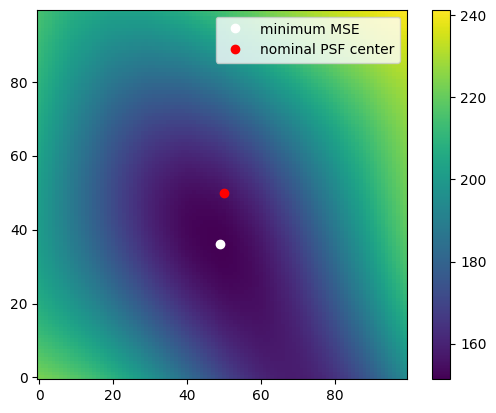

In [25]:
Z = np.array(Z)
a = np.unravel_index(Z.argmin(),y.shape)
print(a)

rad_center = np.array([a[1],a[0]])
print(f'est radiation center at pixel index {rad_center}')

Z = np.reshape(Z,y.shape)
plt.imshow(Z,origin='lower')
plt.plot(a[1],a[0],'o',color='white',label='minimum MSE')
plt.plot(search_size/2,search_size/2,'o',color='red',label='nominal PSF center')
plt.legend()
plt.colorbar()

### Upsampling

Text(0.5, 1.0, 'After Upsampling')

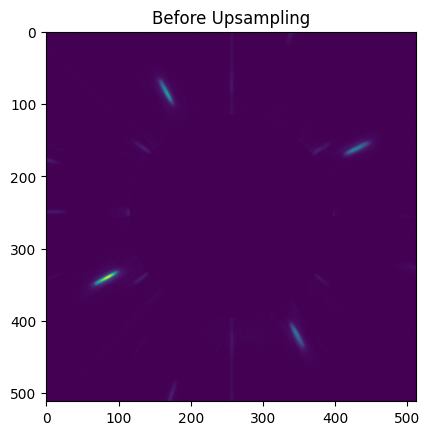

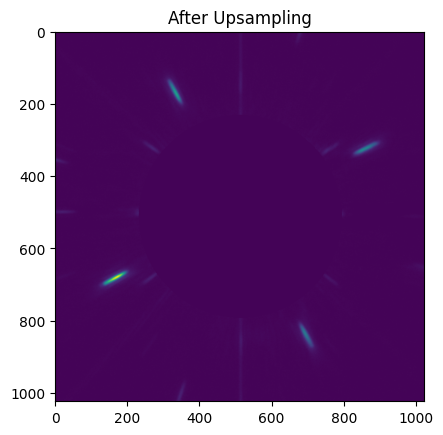

In [17]:
img = step[26]
img = ADC.crop_image(img,extent=512,mask_diam=80)
psf = np.array(img.shaped)

new_psf = scipy.ndimage.zoom(psf,2,order=3)

plt.imshow(psf)
plt.title('Before Upsampling')
plt.figure()
plt.imshow(new_psf)
plt.title('After Upsampling')

In [26]:
center = new_psf.shape[0]/2
search_size = 100
y, x = np.meshgrid(
    np.arange(center - search_size/2, center + search_size/2),
    np.arange(center - search_size/2, center + search_size/2),
    indexing="ij"
)
indices = np.stack([y.ravel(), x.ravel()], axis=1) #raster scan indices

Z = []

for index in indices:
    psf_stretched = radial_stretch_from_point(new_psf,1.1,center=index)
    mse = np.sum((new_psf - psf_stretched)**2)
    Z.append(mse)

(np.int64(24), np.int64(46))
est radiation center at pixel index [46 24]


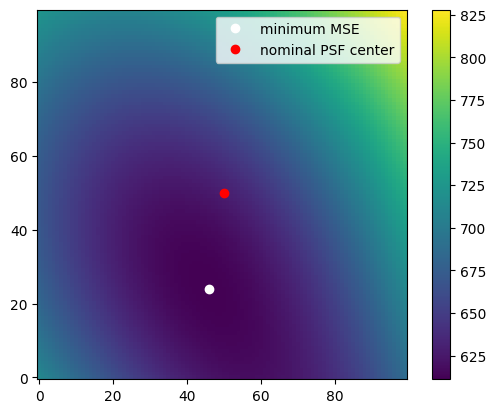

In [27]:
Z = np.array(Z)
a = np.unravel_index(Z.argmin(),y.shape)
print(a)

rad_center = np.array([a[1],a[0]])
print(f'est radiation center at pixel index {rad_center}')

Z = np.reshape(Z,y.shape)
plt.imshow(Z,origin='lower')
plt.plot(a[1],a[0],'o',color='white',label='minimum MSE')
plt.plot(search_size/2,search_size/2,'o',color='red',label='nominal PSF center')
plt.legend()
plt.colorbar()